In [1]:
import pandas as pd
import xarray as xr
import rasterio as rs
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import ast
import seaborn as sns
import json
import geopandas
from cartopy.io import shapereader
import cartopy.crs as ccrs
import matplotlib.colors as mcolors
import importlib

import cartopy.crs as ccrs
import geopandas
from cartopy.io import shapereader
countries_polygons = geopandas.read_file(shapereader.natural_earth(resolution='10m', category='cultural', name='admin_0_countries'))

species_list = ['Abies_alba', 'Acer_campestre', 'Acer_pseudoplatanus', 'Alnus_glutinosa', 'Alnus_incana', 'Betula_pendula', 'Betula_pubescens', 'Carpinus_betulus', 'Corylus_avellana', 'Fagus_sylvatica', 'Fraxinus_excelsior', 'Picea_abies', 'Pinus_halepensis', 'Pinus_nigra', 'Pinus_pinaster', 'Pinus_sylvestris', 'Populus_tremula', 'Prunus_avium', 'Quercus_ilex', 'Quercus_petraea', 'Quercus_pubescens', 'Quercus_robur', 'Quercus_suber', 'Sorbus_aucuparia']

# bands start at 1, not 0!
band_names = {1: 'historical', 2: 'present', 5: 'ssp1', 6: 'ssp1a', 9: 'ssp2', 10: 'ssp2a', 13: 'ssp5', 14: 'ssp5a'}
opt_scenarios = list(band_names.values())[2:]

import amoc_computations as amoc_comp
import amoc_plots
import amoc_optimization
import get_amoc_data
import importlib
importlib.reload(amoc_plots)
importlib.reload(get_amoc_data)
importlib.reload(amoc_comp)

<module 'amoc_computations' from '/home/konni/Documents/phd/amoc_shutdown/amoc_computations.py'>

# Read Optimized Data and Occurrences

In [2]:
SKIP = 1000 # only read every nth row, 1000 for quick plotting, 1 for full dataset

In [3]:
OPTIMIZED_DATA = WORKING_DIR + "all_optimized.csv.gz" # TODO
OCCURRENCES = 'data/heubel_occurrences.csv'

In [4]:
rows = []
for chunk in pd.read_csv(OPTIMIZED_DATA, sep=';', chunksize=1000):
    rows.append(chunk.iloc[::SKIP])
df_final_optimized = pd.concat(rows, ignore_index=True)

In [5]:
assert np.all(df_final_optimized['opt_portfolio_min_prob'] + 0.000000001 >= df_final_optimized['opt_single_species_min_prob']) , "Error! Portfolio has worse suitability than single species!"

In [6]:
def string_to_dict(s):
    cleaned = s.replace('np.float64(', '').replace(')', '')
    return ast.literal_eval(cleaned)

df_final_optimized['opt_portfolio'] = df_final_optimized['opt_portfolio'].apply(string_to_dict)

In [7]:
heubel = pd.read_csv(OCCURRENCES, sep=',').rename(columns={'LON': 'lon', 'LAT': 'lat'})

heubel['SPECIES_NAME_NORM'] = heubel['species'].str.replace(' ', '_')
heubel_amoc_species = heubel[heubel['SPECIES_NAME_NORM'].isin(species_list)].copy()
heubel_amoc_species = heubel_amoc_species[heubel_amoc_species['lat'] > 36] # cut out canary islands etc

column_name = heubel_amoc_species['SPECIES_NAME_NORM'] + '-present'
occurrence_24_species_dataset = heubel_amoc_species.copy()

# Align optimized data with occurrence dataset

In [8]:
# for each occurrence, we want to find the closest suitability row, and get the corresponding suitability of the mauri species.
from scipy.spatial import cKDTree
suitability = df_final_optimized.copy().reset_index()
suitability_coords = suitability[['x', 'y']].values
# kdtree of the suitability coordinates, to find the closest to a mauri coordinate
tree = cKDTree(suitability_coords)
# for each occurrence coordinate, find the closest suitability entry
heubel_coords = occurrence_24_species_dataset[['lon', 'lat']].values
distances, indices = tree.query(heubel_coords, k=1)

In [9]:
ordered_subset = suitability.iloc[indices]
occurrence_24_species_dataset['amoc_coords'] = indices
occurrence_24_species_dataset['amoc_distance'] = distances
occurrence_24_species_dataset['amoc_lon'] = suitability.iloc[indices]['x'].values
occurrence_24_species_dataset['amoc_lat'] = suitability.iloc[indices]['y'].values


for scenario in opt_scenarios + ['historical', 'present']:
    colname_per_row = occurrence_24_species_dataset['SPECIES_NAME_NORM'] + "-" + scenario
    occurrence_24_species_dataset['occurring_species_suitability_' + scenario] = [ordered_subset.iloc[i][colname_per_row.iloc[i]] for i in range(len(ordered_subset))]

occurrence_24_species_dataset['future_min_suitability'] = occurrence_24_species_dataset[['occurring_species_suitability_' + scenario for scenario in opt_scenarios]].min(axis=1)
occurrence_24_species_dataset['future_min_suitability_amoc_on'] = occurrence_24_species_dataset[['occurring_species_suitability_' + scenario for scenario in opt_scenarios if not scenario.endswith('a')]].min(axis=1)
occurrence_24_species_dataset['future_mean_suitability'] = occurrence_24_species_dataset[['occurring_species_suitability_' + scenario for scenario in opt_scenarios]].mean(axis=1)
# takes 3m

# get the species with highest present suitability for a pixel (there could be multiple trees on one pixel)
deduped_occurrence_24_species_dataset = occurrence_24_species_dataset.loc[
    occurrence_24_species_dataset.groupby(['lon', 'lat'])['occurring_species_suitability_present'].idxmax()
].reset_index(drop=True)

In [10]:
filtered_df = df_final_optimized.merge(
    deduped_occurrence_24_species_dataset,
    left_on=['x', 'y'],
    right_on=['amoc_lon', 'amoc_lat'],
    how='inner'
)

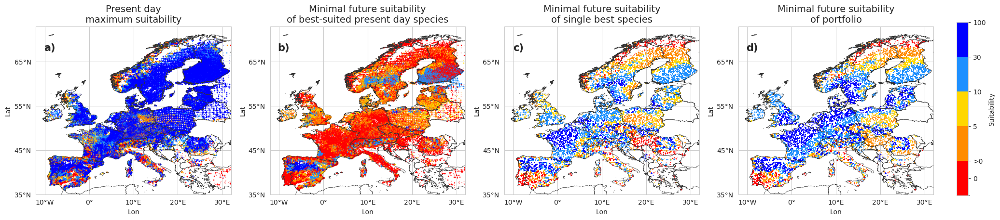

In [11]:
importlib.reload(amoc_plots)
amoc_plots.plot_present_historical_single_portfolio(deduped_occurrence_24_species_dataset, filtered_df, filename=None)

# Suitability numbers

In [12]:
LOW_THRESHOLD = 5

print('Share of historic marginal suitability:', len(occurrence_24_species_dataset[occurrence_24_species_dataset['occurring_species_suitability_historical'] < LOW_THRESHOLD]) / len(occurrence_24_species_dataset))
print('Share of present marginal suitability:', len(occurrence_24_species_dataset[occurrence_24_species_dataset['occurring_species_suitability_present'] < LOW_THRESHOLD]) / len(occurrence_24_species_dataset))
print('Share of future marginal suitability:', len(occurrence_24_species_dataset[occurrence_24_species_dataset['future_min_suitability'] < LOW_THRESHOLD]) / len(occurrence_24_species_dataset))
print('Share of future amoc on marginal suitability:', len(occurrence_24_species_dataset[occurrence_24_species_dataset['future_min_suitability_amoc_on'] < LOW_THRESHOLD]) / len(occurrence_24_species_dataset))
print('Share of future marginal suitability for best species:', len(filtered_df[filtered_df['opt_single_species_min_prob'] < LOW_THRESHOLD]) / len(filtered_df))
print('Share of future marginal suitability for portfolio:', len(filtered_df[filtered_df['opt_portfolio_min_prob'] < LOW_THRESHOLD]) / len(filtered_df))

Share of historic marginal suitability: 0.09172597981817943
Share of present marginal suitability: 0.15656792522689983
Share of future marginal suitability: 0.7931917836797522
Share of future amoc on marginal suitability: 0.6415424489205226
Share of future marginal suitability for best species: 0.2125703710044964
Share of future marginal suitability for portfolio: 0.16289384322502007


## Suitabilities across scenarios

/tmp/ipykernel_27522/4140227836.py:6: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1, 6, figsize=(40, 6))


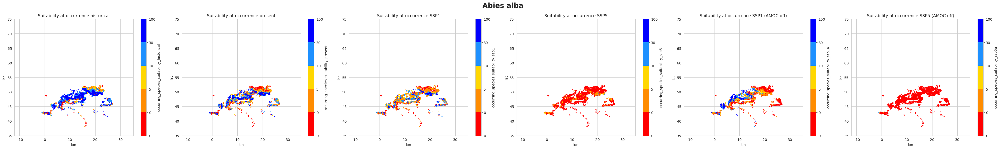

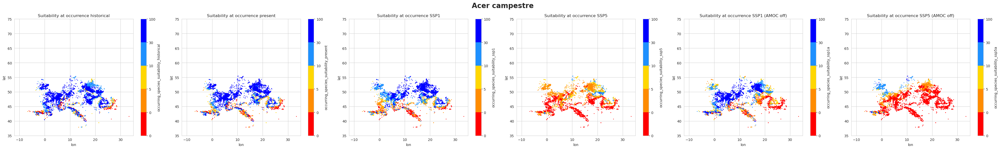

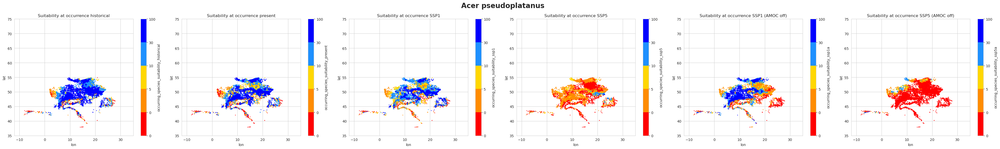

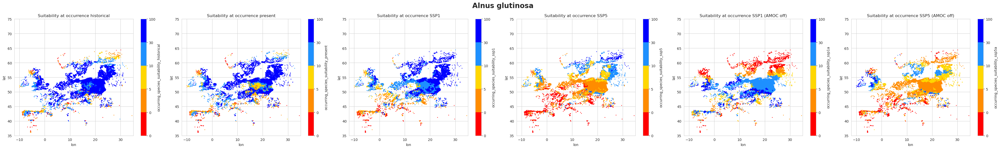

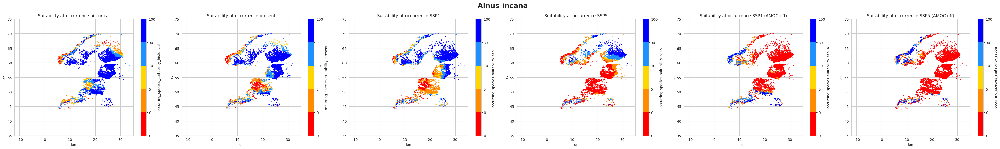

...

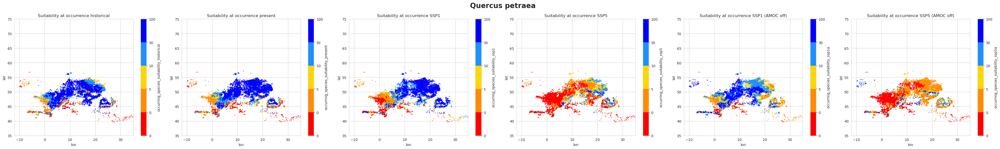

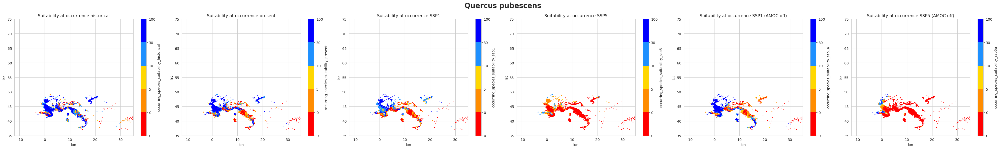

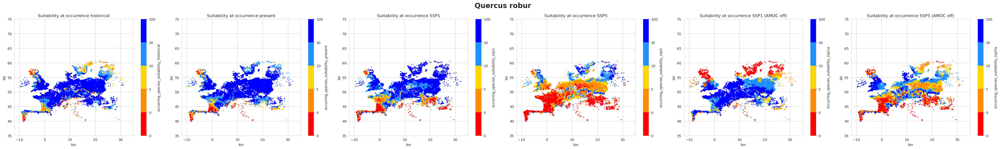

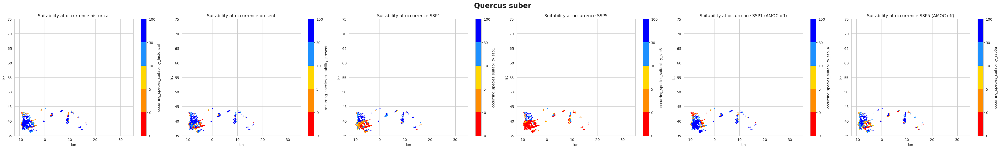

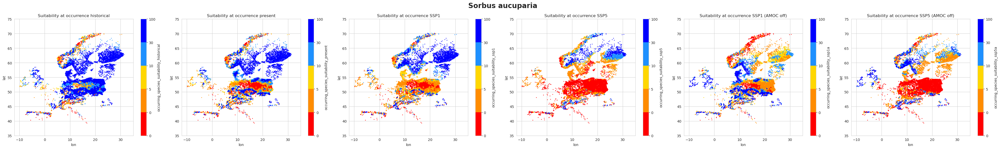

In [13]:
importlib.reload(amoc_plots)
number_of_false_negatives = []
number_of_total_observations = []

for species in species_list:
    fig, ax = plt.subplots(1, 6, figsize=(40, 6))
    species_occurrences = occurrence_24_species_dataset[occurrence_24_species_dataset['SPECIES_NAME_NORM'] == species]

    all_pixels = len(species_occurrences)

    species_occurrences_with_suitabilities = occurrence_24_species_dataset[occurrence_24_species_dataset['SPECIES_NAME_NORM'] == species].copy()
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_historical', ax=ax[0], s=1, title='Suitability at occurrence historical', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_present', ax=ax[1], s=1, title='Suitability at occurrence present', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_ssp1', ax=ax[2], s=1, title='Suitability at occurrence SSP1', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_ssp5', ax=ax[3], s=1, title='Suitability at occurrence SSP5', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_ssp1a', ax=ax[4], s=1, title='Suitability at occurrence SSP1 (AMOC off)', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)
    species_occurrences_with_suitabilities.reset_index().plot.scatter(x='lon', y='lat', c='occurring_species_suitability_ssp5a', ax=ax[5], s=1, title='Suitability at occurrence SSP5 (AMOC off)', cmap=amoc_plots.prob_cmap, norm=amoc_plots.prob_norm)

    for axx in ax:
        axx.set_xlim([-12, 35])
        axx.set_ylim([35, 75])

    fig.suptitle(species.replace('_', ' '), fontsize=20, fontweight='bold')
    fig.tight_layout()

# Extrapolated to continent

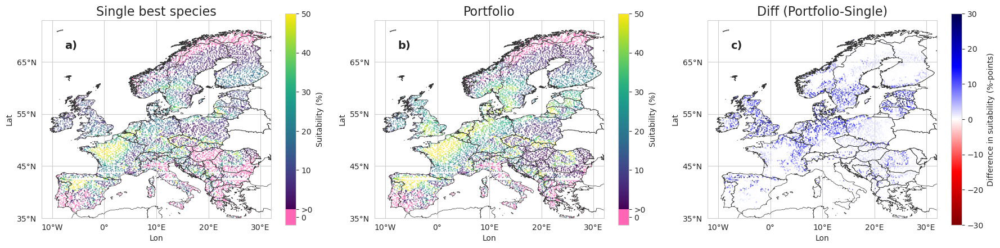

In [14]:
amoc_plots.plot_single_vs_portfolio(df_final_optimized, titleaddition='ensemble mean, all scenarios', filename=None)

## Explanation of "zero" areas
Hungary: For **every** species, there is a scenario where its suitability is zero. Therefore, only the portfolio approach can provide a minimal suitability > 0.

Spain/Portugal: There are scenarios where no species will thrive. So also the portfolio will not help in such a case.

## Suitability numbers

In [15]:
improved_pixels = df_final_optimized[df_final_optimized['opt_portfolio_min_prob'] > df_final_optimized['opt_single_species_min_prob']]
len(improved_pixels) / len(df_final_optimized)

0.582286432160804

In [16]:
df_final_optimized['opt_portfolio_min_prob'].mean(), df_final_optimized['opt_single_species_min_prob'].mean()

(np.float64(18.24961407641532), np.float64(13.387772194304858))

In [17]:
LOW_THRESHOLD = 5

print('Share of future marginal suitability for best species:', len(df_final_optimized[df_final_optimized['opt_single_species_min_prob'] < LOW_THRESHOLD]) / len(df_final_optimized))
print('Share of future marginal suitability for portfolio:', len(df_final_optimized[df_final_optimized['opt_portfolio_min_prob'] < LOW_THRESHOLD]) / len(df_final_optimized))

print('Share of future zero suitability for best species:', len(df_final_optimized[df_final_optimized['opt_single_species_min_prob'] < 0.1]) / len(df_final_optimized))
print('Share of future zero suitability for portfolio:', len(df_final_optimized[df_final_optimized['opt_portfolio_min_prob'] < 0.1]) / len(df_final_optimized))

Share of future marginal suitability for best species: 0.37154522613065327
Share of future marginal suitability for portfolio: 0.30695142378559465
Share of future zero suitability for best species: 0.18729061976549413
Share of future zero suitability for portfolio: 0.12405778894472362


# Proposed species

In [18]:
df_final_optimized_at_least_two = df_final_optimized[df_final_optimized['opt_portfolio'].map(len) > 1].copy()

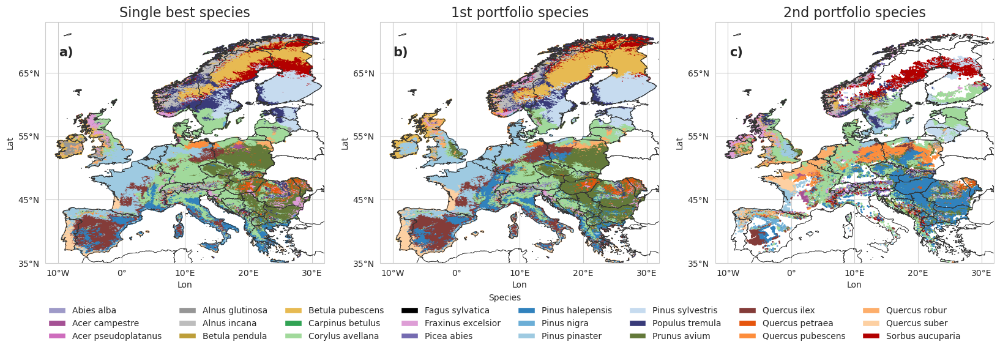

In [35]:
importlib.reload(amoc_plots)
from matplotlib.patches import Patch
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

fig, ax = plt.subplots(1, 3, figsize=(20, 12), subplot_kw={'projection': ccrs.PlateCarree()})

df_final_optimized['top'] = df_final_optimized['opt_portfolio'].map(lambda pf: int(sorted(pf.items(), key=lambda item: item[1], reverse=True)[0][0]))
df_final_optimized_at_least_two['second'] = df_final_optimized_at_least_two['opt_portfolio'].map(lambda pf: int(sorted(pf.items(), key=lambda item: item[1], reverse=True)[1][0]))

amoc_plots.plot_single_best_species(ax[0], df_final_optimized, species_list, colorbar=False)
amoc_plots.plot_single_best_species(ax[1], df_final_optimized, species_list, column='top', colorbar=False)
amoc_plots.plot_single_best_species(ax[2], df_final_optimized_at_least_two, species_list, column='second', colorbar=False)

legend_elements = [
    Patch(facecolor=amoc_plots.species_to_color[species], label=species.replace('_', ' '))
    for species in species_list
]

fig.legend(
    handles=legend_elements,
    title="Species",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),  # center below the subplots
    ncol=len(species_list)/3,
    frameon=False
)

fig.subplots_adjust(bottom=-0.28)

ax[0].set_title('Single best species', fontsize=16)
ax[1].set_title('1st portfolio species', fontsize=16)
ax[2].set_title('2nd portfolio species', fontsize=16)

for idx, letter in enumerate(['a', 'b', 'c']):
    ax[idx].text(0.1, 0.9, letter + ')', fontsize=15, weight='bold',
                 va='top', ha='right', transform=ax[idx].transAxes)
    ax[idx].add_geometries(
        countries_polygons['geometry'], crs=ccrs.PlateCarree(),
        facecolor='none', edgecolor='0.2', linewidth=0.5
    )
    ax[idx].set_extent(amoc_plots.europe_extent, crs=ccrs.PlateCarree())
    ax[idx].set_ylabel('Lat')
    ax[idx].set_xlabel('Lon')
    ax[idx].set_xticks([-10, 0, 10, 20, 30], crs=ccrs.PlateCarree())
    ax[idx].set_yticks([35, 45, 55, 65], crs=ccrs.PlateCarree())
    ax[idx].xaxis.set_major_formatter(LONGITUDE_FORMATTER)
    ax[idx].yaxis.set_major_formatter(LATITUDE_FORMATTER)

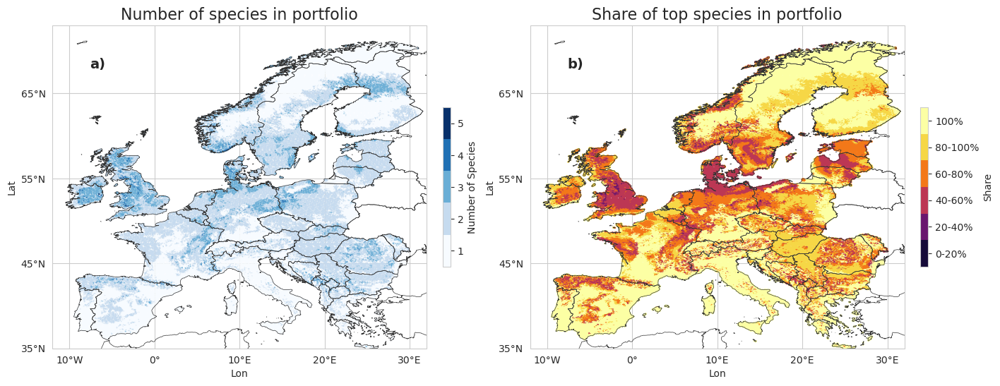

In [36]:
importlib.reload(amoc_plots)
amoc_plots.plot_n_species_of_portfolio(df_final_optimized, filename=WORKING_DIR + 'figures/full_n_species_newamoc.png')